## Read the data

In [1]:
import collections

import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/evaluation_results/"
TARGET_LENGTHS = [9, 10]

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01',  'HLA-A*02:01']
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01']

# Read models

In [4]:
from hmm_logic_methods import load_model

In [5]:
import itertools

RUNS = 2
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
max_target_length = max(TARGET_LENGTHS)
total_splits = 1


name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type




# states = 3
combinations_size = len(ALLELES)
# combinations_size = 2
# # MODELS_PATH = f"experiment_results/iterative_all_alleles_{states}perposition/"
# # MODELS_PATH = f"experiment_results/iterative_alleles_{states}perposition/"
# MODELS_PATH = f"experiment_results/iterative_alleles_{states}perposition_pc10/"
MIXED_ALLELES = list()
for combination in itertools.combinations(ALLELES, combinations_size):
    allele_name = "+".join(combination)
    # allele_name = f"{allele_name1}+{allele_name2}"
    MIXED_ALLELES.append(allele_name)
#
# for allele_name in MIXED_ALLELES:
#     target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
#     for run_num_b in range(RUNS):
#         for split_num_b in range(total_splits):
#             #bw
#             bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}"
#             populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})")
#             #bwv
#             bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}_plus_viterbi"
#             populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})")
#             #v
#             v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}"
#             populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})")


MODELS_PATH = f"experiment_results/alleles_with_groups_balanced/"
total_splits = 1
states = 25
for allele_name in MIXED_ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for run_num_b in range(RUNS):
        for split_num_b in range(total_splits):
            #bw
            bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}"
            populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})")
            #bwv
            bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_plus_viterbi"
            populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})")
            #v
            v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{target_allele_name}-{split_num_b}"
            populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})")


for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [6]:
per_name_binding_model.keys()

dict_keys(['0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0', '0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi', '0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0', '1_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0', '1_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi', '1_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0'])

# Select mixed models BW,BWV, and V

In [7]:
import importlib
import hmm_logic_methods
importlib.reload(hmm_logic_methods)

<module 'hmm_logic_methods' from 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\hmm_logic_methods.py'>

In [8]:
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01']

In [9]:
# combination = "HLA_A_01_01+HLA_A_02_01+HLA_A_03_01+HLA_B_07_02+HLA_B_27_05"
# selected_alleles = ['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-B*07:02', 'HLA-B*27:05']
# selected_alleles = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-B*07:02']
selected_alleles = ['HLA-A*01:01', 'HLA-A*03:01',  'HLA-A*02:01']
combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')

# iterative models
# mixed_model_bw =f'0_run-9-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0_iterations_to_length_9'
# mixed_model_bwv = f'0_run-9-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0_iterations_to_length_9_plus_viterbi'
# mixed_model_v = f'0_run-9-{states}-st-viterbi-alg-5-min_iters_model-{combination}-0_iterations_to_length_9'
#

# simple models
# states = 25
mixed_model_bw =f'0_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0'
mixed_model_bwv = f'0_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0_plus_viterbi'
mixed_model_v = f'0_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{combination}-0'

In [10]:
model_bw = per_name_binding_model[mixed_model_bw]
model_bwv = per_name_binding_model[mixed_model_bwv]
model_v = per_name_binding_model[mixed_model_v]

model_list = [model_bw, model_bwv, model_v]


# Calculate paths embeddings (16.03.2022)

## Preparation: Read predefined paths df

In [11]:
def load_paths_df(model, type='viterbi'):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES = name_to_model_root[model.name] + model.name
    if type == 'viterbi':
        paths_df = pd.read_csv("{}/viterbi_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";")
    else:
        paths_df = pd.read_csv("{}/total_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";")
    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  paths_df


In [12]:
df_bw_paths = load_paths_df(model_bw)
df_bwv_paths = load_paths_df(model_bwv)
df_v_paths = load_paths_df(model_v)

model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0


In [13]:
df_bw_paths

,path,prob,normalized_prob,len
0,grouped_model-start>s002>s003>s006>s013>s010>s...,-4.950725,-0.412560,10
1,grouped_model-start>s002>s003>s006>s013>s012>s...,-5.051977,-0.420998,10
2,grouped_model-start>s002>s003>s006>s013>s010>s...,-5.135306,-0.427942,10
3,grouped_model-start>s002>s003>s006>s013>s012>s...,-5.236558,-0.436380,10
4,grouped_model-start>s002>s003>s006>s013>s010>s...,-4.862546,-0.442050,9
...,...,...,...,...
1513,grouped_model-start>s004>s002>s008>s009>s013>s...,-15.345073,-1.278756,10
1514,grouped_model-start>s000>s002>s008>s009>s013>s...,-15.362351,-1.280196,10
1515,grouped_model-start>s000>s002>s003>s006>s013>s...,-15.442132,-1.286844,10
1516,grouped_model-start>s001>s000>s008>s006>s005>s...,-16.265387,-1.355449,10


In [14]:
# Get top paths
from hmm_logic_methods import  get_model_representation


In [15]:
# %%time
# df_bw_paths, edge_to_prob_bw = get_all_paths_with_probs(model_bw, cutoff=max(TARGET_LENGTHS), precision=3, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))
# df_bwv_paths, edge_to_prob_bwv = get_all_paths_with_probs(model_bwv, cutoff=max(TARGET_LENGTHS), precision=3, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))
# df_v_paths, edge_to_prob_v = get_all_paths_with_probs(model_v, cutoff=max(TARGET_LENGTHS), precision=2, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))

## Make peptide sets (not intersected)

In [16]:
%%time
from collections import defaultdict
# target_length = 9
TOP=2000

selected_alleles = selected_alleles


per_allele_representations_train = dict()
per_allele_representations_test = dict()
per_name_representation_train = dict()
per_name_representation_test = dict()

def handle_intersections(per_allele_per_kfold_per_length_peptides):
    per_allele_result_peptide_sets =  defaultdict(set)
    per_allele_per_length_peptide_sets =  defaultdict(set)
    PER_LENGTH_SIZE = {target_length: min([len(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length]) for allele_name in selected_alleles]) for target_length in TARGET_LENGTHS}
    print(PER_LENGTH_SIZE)
    for target_length in TARGET_LENGTHS:
        print(f"Length {target_length}")
        for allele_name in selected_alleles:
            print(f"initial length for  allele { allele_name} TL {target_length} is {len(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length])}")
            peptides = set(np.random.choice(per_allele_per_kfold_per_length_peptides[allele_name][0][target_length], size=PER_LENGTH_SIZE[target_length], replace=False))
            print(f"Selected {len(peptides)} peptides")
            per_allele_per_length_peptide_sets[allele_name] = peptides
        # get all intersections
        intersections = list()
        for i in range(len(selected_alleles)):
            for j in range(i + 1, len(selected_alleles)):
                set1 = per_allele_per_length_peptide_sets[selected_alleles[i]]
                set2 = per_allele_per_length_peptide_sets[selected_alleles[j]]
                intersect = set1.intersection(set2)
                print(f"{selected_alleles[i]} intersect {selected_alleles[j]} - {len(intersect)}")
                intersections.append(intersect)
        # delete all intersections
        for allele_name, peptide_set in per_allele_per_length_peptide_sets.items():
            print(f"Allele {allele_name}: deleted", end=" ")
            initial_length = len(peptide_set)
            for intersect in intersections:
                peptide_set = peptide_set.difference(intersect)
            result_length = len(peptide_set)
            print(f" {initial_length - result_length} of intersected peptides")
            per_allele_result_peptide_sets[allele_name] = per_allele_result_peptide_sets[allele_name].union(peptide_set)
    return per_allele_result_peptide_sets

print("Train")
per_allele_peptide_train_sets = handle_intersections(per_allele_per_kfold_per_length_binders_train)
print("Test")
per_allele_peptide_test_sets = handle_intersections(per_allele_per_kfold_per_length_binders_test)



train_peptides_b = set(set().union(*per_allele_peptide_train_sets.values()))

test_peptides_b = set(set().union(*per_allele_peptide_test_sets.values()))

print(f"Train {len(train_peptides_b)}, Test {len(test_peptides_b)}")





# for allele_name in selectes_alleles:
#     for allele_name in selectes_alleles:
#
# train_peptides_b2 =  set(per_allele_per_kfold_per_length_binders_train[allele_2][0][target_length])
#
# intersect = train_peptides_b1.intersection(train_peptides_b2)
# print("Do not count intersection peptides ", len(intersect))
# train_peptides_b1 = train_peptides_b1.difference(intersect)
# train_peptides_b2 = train_peptides_b2.difference(intersect)
#
# train_peptides_b = train_peptides_b1.union(train_peptides_b2)
# # train_peptides_b = train_peptides_b1.copy()
# # train_peptides_b = train_peptides_b.update(train_peptides_b2)
# train_allele_1_cnt = len(train_peptides_b1)
# train_allele_2_cnt = len(train_peptides_b2)
#
# test_peptides_b1 =  set(per_allele_per_kfold_per_length_binders_test[allele_1][0][target_length])
# test_peptides_b2 =  set(per_allele_per_kfold_per_length_binders_test[allele_2][0][target_length])
#
# intersect = test_peptides_b1.intersection(test_peptides_b2)
# print("Do not count intersection test peptides ", len(intersect))
# test_peptides_b1 = test_peptides_b1.difference(intersect)
# test_peptides_b2 = test_peptides_b2.difference(intersect)
#
# test_peptides_b = test_peptides_b1.union(test_peptides_b2)
#
# test_allele_1_cnt = len(test_peptides_b1)
# test_allele_2_cnt = len(test_peptides_b2)

Train
{9: 5052, 10: 2184}
Length 9
initial length for  allele HLA-A*01:01 TL 9 is 5052
Selected 4842 peptides
initial length for  allele HLA-A*03:01 TL 9 is 5132
Selected 4584 peptides
initial length for  allele HLA-A*02:01 TL 9 is 24309
Selected 4939 peptides
HLA-A*01:01 intersect HLA-A*03:01 - 122
HLA-A*01:01 intersect HLA-A*02:01 - 73
HLA-A*03:01 intersect HLA-A*02:01 - 55
Allele HLA-A*01:01: deleted  193 of intersected peptides
Allele HLA-A*03:01: deleted  175 of intersected peptides
Allele HLA-A*02:01: deleted  126 of intersected peptides
Length 10
initial length for  allele HLA-A*01:01 TL 10 is 2464
Selected 2178 peptides
initial length for  allele HLA-A*03:01 TL 10 is 2184
Selected 2157 peptides
initial length for  allele HLA-A*02:01 TL 10 is 7129
Selected 2094 peptides
HLA-A*01:01 intersect HLA-A*03:01 - 13
HLA-A*01:01 intersect HLA-A*02:01 - 18
HLA-A*03:01 intersect HLA-A*02:01 - 16
Allele HLA-A*01:01: deleted  31 of intersected peptides
Allele HLA-A*03:01: deleted  29 of inte

In [17]:

print("Train")

train_peptides_repr_data_b_model_bw, check_paths_df, check_emission_matrix, check_name_to_index = \
    get_model_representation(model_bw, set(train_peptides_b), paths_df=df_bw_paths, edge_value="log_probability", top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_bw.loc[peptide_set, 'allele'] = allele_name


train_peptides_repr_data_b_model_bwv, _, _, _ = \
    get_model_representation(model_bwv, set(train_peptides_b), paths_df=df_bwv_paths, edge_value="log_probability", top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_bwv.loc[peptide_set, 'allele'] = allele_name



train_peptides_repr_data_b_model_v,  _, _, _ = \
    get_model_representation(model_v, set(train_peptides_b), paths_df=df_v_paths, edge_value="log_probability", top_paths=TOP, precision=2)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_train_sets[allele_name]
    train_peptides_repr_data_b_model_v.loc[peptide_set, 'allele'] = allele_name


print("Test")
test_peptides_repr_data_b_model_bw,  _, _, _= \
    get_model_representation(model_bw, set(test_peptides_b), paths_df=df_bw_paths, edge_value="log_probability",  top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_bw.loc[peptide_set, 'allele'] = allele_name

test_peptides_repr_data_b_model_bwv,  _, _, _ = \
    get_model_representation(model_bwv, set(test_peptides_b), paths_df=df_bwv_paths, edge_value="log_probability",  top_paths=TOP, precision=3)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_bwv.loc[peptide_set, 'allele'] = allele_name


test_peptides_repr_data_b_model_v,  _, _, _= \
    get_model_representation(model_v, set(test_peptides_b), paths_df=df_v_paths, edge_value="log_probability",  top_paths=TOP, precision=2)
for allele_name in selected_alleles:
    peptide_set = per_allele_peptide_test_sets[allele_name]
    test_peptides_repr_data_b_model_v.loc[peptide_set, 'allele'] = allele_name



per_name_representation_train["bw"] = {"db": train_peptides_repr_data_b_model_bw  }
per_name_representation_train["bwv"] = {"db": train_peptides_repr_data_b_model_bwv  }
per_name_representation_train["v"] = {"db": train_peptides_repr_data_b_model_v  }
per_name_representation_test["bw"] = {"db": test_peptides_repr_data_b_model_bw  }
per_name_representation_test["bwv"] = {"db": test_peptides_repr_data_b_model_bwv  }
per_name_representation_test["v"] = {"db": test_peptides_repr_data_b_model_v  }


Train
Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|██████████████████████████████████████████████████████████████████████████████| 1518/1518 [02:15<00:00, 11.23it/s]


Finished
Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
Took only 2000 top paths
	Calculate probs for peptides


100%|████████████████████████████████████████████████████████████████████████████████| 862/862 [01:16<00:00, 11.20it/s]


Finished
Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [02:57<00:00, 11.26it/s]


... (3 outputs left out)

100%|████████████████████████████████████████████████████████████████████████████████| 862/862 [00:20<00:00, 43.08it/s]


Finished
Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
Took only 2000 top paths
	Calculate probs for peptides


100%|██████████████████████████████████████████████████████████████████████████████| 2000/2000 [00:46<00:00, 43.19it/s]


Finished


In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

## Heatmap

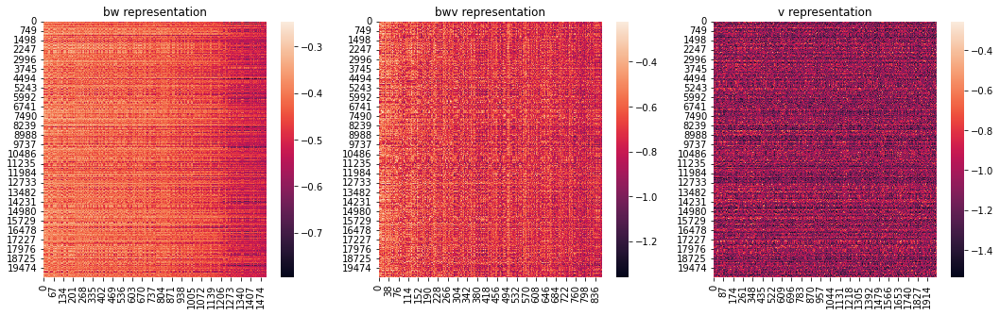

In [19]:
fig, axes = plt.subplots(nrows=1, ncols= 3, figsize=(18, 5))

representations= ['bw', 'bwv', 'v']

for i,representation in enumerate(representations):
    data = per_name_representation_train[representation]['db'].drop(columns=["allele"])
    ax = sns.heatmap(data=data.values, ax=axes[i])
    ax.set_title(f"{representation} representation")
    plt.tight_layout



In [26]:
df_v_paths

,path,prob,normalized_prob,len
0,grouped_model-start>s000>s001>s004>s009>s005>s...,-10.940424,-0.994584,9
1,grouped_model-start>s000>s001>s004>s009>s005>s...,-11.059608,-1.005419,9
2,grouped_model-start>s000>s001>s000>s001>s004>s...,-11.105173,-1.009561,9
3,grouped_model-start>s000>s001>s004>s001>s004>s...,-11.250536,-1.022776,9
4,grouped_model-start>s000>s001>s004>s009>s005>s...,-11.281128,-1.025557,9
...,...,...,...,...
683017,grouped_model-start>s002>s000>s002>s004>s003>s...,-30.068949,-2.505746,10
683018,grouped_model-start>s002>s001>s003>s004>s007>s...,-27.607725,-2.509793,9
683019,grouped_model-start>s004>s000>s003>s008>s014>s...,-30.442864,-2.536905,10
683020,grouped_model-start>s003>s008>s014>s018>s016>s...,-28.088904,-2.553537,9


In [72]:
data.describe()

,0,1,2,3,4,5,6,7,8,9,...,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999
count,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,...,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000,13823.000000
mean,-0.729830,-0.738877,-0.718235,-0.713167,-0.742837,-0.718283,-0.736571,-0.706450,-0.762445,-0.753917,...,-0.768537,-0.779060,-0.779120,-0.763310,-0.755208,-0.803481,-0.760997,-0.762431,-0.772235,-0.747236
std,0.104619,0.102249,0.104309,0.104845,0.099927,0.098185,0.105249,0.099809,0.112647,0.096607,...,0.107388,0.105640,0.096006,0.096573,0.092751,0.108438,0.097412,0.098690,0.095258,0.098727
min,-1.019310,-1.021340,-1.007974,-1.010116,-1.020765,-1.045442,-1.021903,-1.004657,-1.019592,-1.055910,...,-1.044713,-1.107851,-1.075114,-1.082093,-1.053922,-1.035931,-1.016143,-1.073189,-1.069401,-1.067213
25%,-0.804630,-0.811748,-0.790348,-0.787342,-0.813646,-0.789951,-0.809463,-0.775939,-0.846269,-0.821488,...,-0.843218,-0.851563,-0.847634,-0.831460,-0.821008,-0.880691,-0.831314,-0.832011,-0.837657,-0.819956
50%,-0.733675,-0.741774,-0.722072,-0.717310,-0.745687,-0.722875,-0.742048,-0.708637,-0.769201,-0.756397,...,-0.771946,-0.780200,-0.781587,-0.767593,-0.757119,-0.805247,-0.765817,-0.765344,-0.773614,-0.750828
75%,-0.659413,-0.671411,-0.647960,-0.641155,-0.676892,-0.652963,-0.667144,-0.637988,-0.688107,-0.688583,...,-0.696955,-0.705895,-0.714423,-0.698508,-0.690445,-0.730517,-0.695918,-0.694486,-0.709408,-0.680736
max,-0.335853,-0.364516,-0.284239,-0.302750,-0.373608,-0.361240,-0.339849,-0.359955,-0.314634,-0.381222,...,-0.283165,-0.374051,-0.374470,-0.350270,-0.318067,-0.347112,-0.395633,-0.374704,-0.409802,-0.318823


## Count Peptides per paths (Not valid for non-sparse data)

In [35]:
df = per_name_representation_train["v"]["db"]
max([len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])

20

<AxesSubplot:>

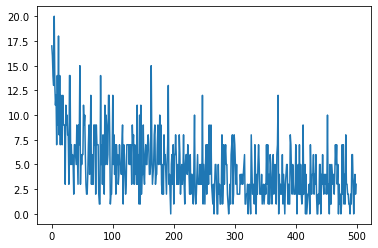

In [36]:
sns.lineplot(x=[i for i in range(len(df.columns) - 1)],y=[len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])

<AxesSubplot:>

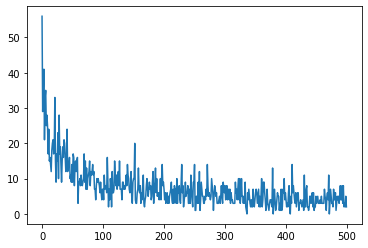

In [37]:
df = per_name_representation_train["bwv"]["db"]
sns.lineplot(x=[i for i in range(len(df.columns) - 1)],y=[len(df[df[i] != -55]) for i in range(len(df.columns) - 1)])


## Plot motifs for top paths

In [77]:
import logomaker
import matplotlib.pyplot as plt
from collections import defaultdict
from mhcgnomes import parse

def check_path_motif(top_paths, representation, length=9, start = 0, threshold=-0.4):
    fig,axes = plt.subplots(figsize=(5*top_paths, 3), nrows=2, ncols=top_paths)
    df = representation[representation.index.str.len() == length]
    for i in range(start, top_paths+start):
        print(i, end=" ")
        filtered_df = df[df[i] > threshold].copy()
        filtered_df['allele'] = filtered_df['allele'].apply(lambda x: parse(x).compact_string())
        counts = defaultdict(int)
        counts.update(dict(filtered_df['allele'].value_counts()))
        # print(counts)
        # print(filtered_df['allele'].value_counts())
        binders_array = filtered_df.index.values
        matrix = logomaker.alignment_to_matrix(binders_array)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[0, i-start])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        compact_alleles = [parse(allele).compact_string() for allele, cnt in sorted(counts.items())]
        counts_list = [i for allele, i in sorted(counts.items())]
        ww_logo.ax.set_title(f"Path {i}, \n {compact_alleles} \n {counts_list}")
        # filtered_df = filtered_df.sort_values(by=path_index)
        filtered_df = filtered_df.sort_values(by='allele')
        sns.boxplot(data=filtered_df, y=filtered_df[i], x='allele', ax=axes[1, i-start])

    print()



0 1 2 3 4 


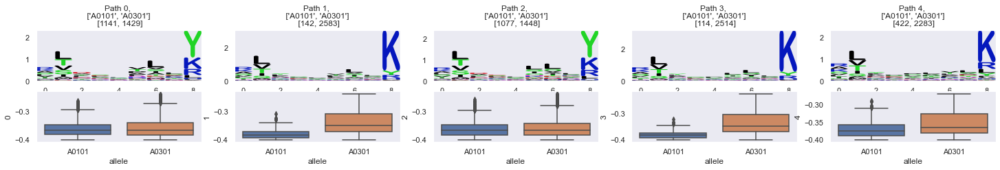

In [78]:
check_path_motif(5, per_name_representation_train["bwv"]["db"], start=0)


0 1 2 3 4 


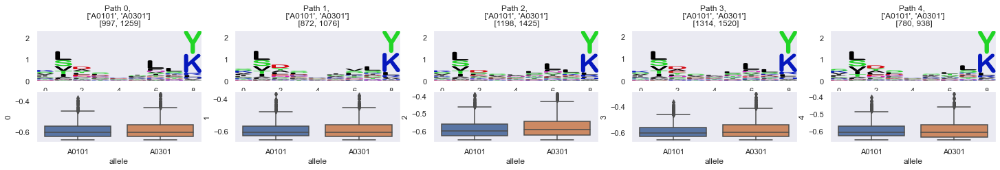

In [84]:
check_path_motif(5, per_name_representation_train["v"]["db"],start=0, threshold=-0.65)

In [87]:
per_name_representation_train["v"]["db"].loc[:,:10]

,0,1,2,3,4,5,6,7,8,9,10
FLNPLISKY,-0.583338,-0.499502,-0.647481,-0.575670,-0.584794,-0.573598,-0.669384,-0.516937,-0.680696,-0.668799,-0.565216
KSGPVIAKR,-0.758313,-0.760343,-0.763332,-0.832571,-0.759769,-0.710017,-0.844359,-0.775959,-0.758595,-0.677126,-0.766933
KSPSEPLIPK,-0.475953,-0.568151,-0.592640,-0.585523,-0.567576,-0.492600,-0.565322,-0.521948,-0.448726,-0.716066,-0.686409
NFLRSIAMLK,-0.734659,-0.736689,-0.892025,-0.808917,-0.736114,-0.743825,-0.820704,-0.713631,-0.808977,-0.640324,-0.895626
AYDPTAPTL,-0.857848,-0.859878,-0.918900,-0.917718,-0.859303,-0.820858,-0.929505,-0.781309,-0.932166,-0.637254,-0.922502
...,...,...,...,...,...,...,...,...,...,...,...
KVYPKAVER,-0.712731,-0.630197,-0.858706,-0.778535,-0.714186,-0.667054,-0.784389,-0.653712,-0.713013,-0.679135,-0.777744
RILLPIVQK,-0.626883,-0.544349,-0.810727,-0.727618,-0.628338,-0.642500,-0.712928,-0.591861,-0.591281,-0.722848,-0.729764
IPDQVIRVF,-0.795142,-0.719681,-0.855073,-0.853891,-0.793273,-0.781202,-0.881187,-0.767336,-0.862664,-0.811152,-0.781184
LVYIFEPEK,-0.801877,-0.803907,-0.820486,-0.740314,-0.803333,-0.807437,-0.810405,-0.742859,-0.766275,-0.629544,-0.824087


0 1 2 3 4 


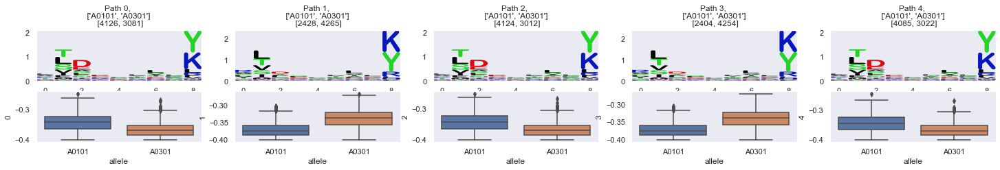

In [83]:
check_path_motif(5, per_name_representation_train["bw"]["db"])

## Compare paths

In [38]:
df = per_name_representation_train["v"]["db"]

In [39]:
from collections import defaultdict
from tqdm import tqdm
per_allele_per_path_cnt = dict()
observed_peptides = set()
paths_cnt = len(df.columns) - 1
for allele_name in selected_alleles:
    per_allele_per_path_cnt[allele_name] = defaultdict(int)
    for path_index in tqdm(range(paths_cnt)):
        filtered_df = df.loc[(df[path_index] != -55) & (df['allele'] == allele_name)]
        for peptide in filtered_df.index:
            if peptide not in observed_peptides:
                per_allele_per_path_cnt[allele_name][path_index] += 1
                observed_peptides.add(peptide)


100%|██████████| 500/500 [00:00<00:00, 661.37it/s]


## Compare peptides per paths for alleles (Not valid for non-sparse data)

In [40]:
from mhcgnomes import parse
cnt_df = pd.DataFrame(index=np.arange(paths_cnt))


for allele_name in selected_alleles:
    allele_counts = np.zeros(shape=(paths_cnt))
    for path_index in range(paths_cnt):
        allele_counts[path_index] = per_allele_per_path_cnt[allele_name][path_index]
    cnt_df[f'allele_{parse(allele_name).compact_string()}_cnt'] =  allele_counts

<AxesSubplot:xlabel='paths', ylabel='cnt of new peptides'>

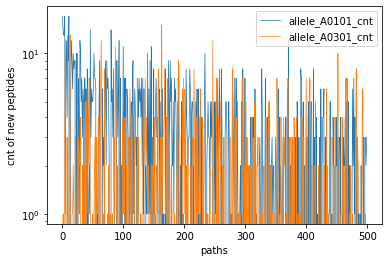

In [41]:
fig, ax = plt.subplots(nrows=1, ncols= 1)
cnt_df.plot(ax= ax, xlabel='paths', ylabel='cnt of new peptides', lw=0.7, alpha=1, logy=True)


<AxesSubplot:xlabel='paths', ylabel='cumulative summ of peptides'>

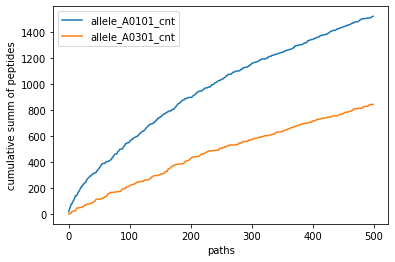

In [42]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(nrows=1, ncols= 1)
cnt_df.cumsum().plot(ax= ax, xlabel='paths', ylabel='cumulative summ of peptides',)

In [233]:
cnt_df.cumsum().loc[7500]

allele_A0101_cnt    4445.0
allele_A0301_cnt    3742.0
Name: 7500, dtype: float64

<AxesSubplot:>

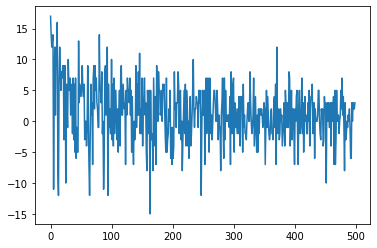

In [43]:
(cnt_df['allele_A0101_cnt'] - cnt_df['allele_A0301_cnt']).plot()

In [45]:
from collections import defaultdict

per_allele_path_counts = dict()
for allele_name in selected_alleles:
    per_allele_path_counts[allele_name] = defaultdict(int)

paths_cnt = len(df.columns) - 1
for path_index in range(paths_cnt):
    counts = df[df[path_index] != -55]['allele'].value_counts()
    for allele_name in selected_alleles:
        if allele_name in counts and counts[allele_name] != 0:
            per_allele_path_counts[allele_name][path_index] = counts[allele_name]

In [46]:
max(per_allele_path_counts[ALLELES[0]].values())

17

## How many peptides we represent with selected TOP

In [47]:
df.loc[(df.drop(columns=['allele']) != -55).any(axis=1)]['allele'].value_counts().sort_values()

HLA-A*03:01     843
HLA-A*01:01    1522
Name: allele, dtype: int64

In [151]:
selected_alleles

['HLA-A*01:01', 'HLA-A*03:01']

In [152]:
path_indexes = [i for i in range(paths_cnt)]
per_allele_df = dict()
for allele_name in selected_alleles:
    allele_cnt = [per_allele_path_counts[allele_name][i] if i in per_allele_path_counts[allele_name] else 0 for i in path_indexes]
    allele_df = pd.DataFrame({"path": path_indexes, "cnt": allele_cnt, "allele": allele_name})
    per_allele_df[allele_name] = allele_df

for allele_name in selected_alleles:
    per_allele_df[allele_name]['diff'] = per_allele_df[selected_alleles[1]]['cnt'] - per_allele_df[selected_alleles[0]]['cnt']

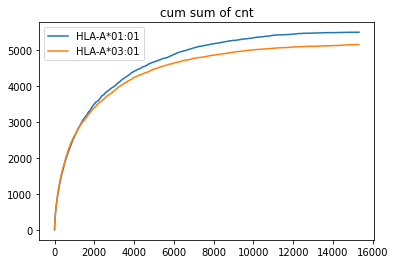

In [153]:


for allele_name in selected_alleles:
    per_allele_df[allele_name]['cnt'].cumsum().plot(ax= ax, x='path', title="cum sum of cnt", legend=True)
ax.legend(selected_alleles);

allele
HLA-A*03:01    4522
HLA-A*01:01    4720
Name: cnt, dtype: int64


<AxesSubplot:xlabel='path', ylabel='cnt'>

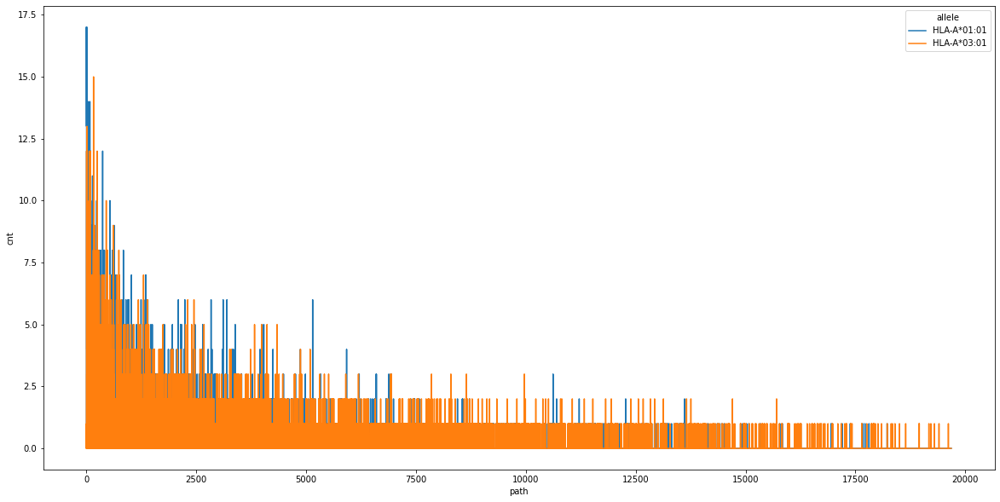

In [143]:

# sns.set_color_codes("pastel")
plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True)
# df = pd.concat([allele1_df, allele2_df]).reset_index(drop=True)
print(df_to_plot.groupby('allele').sum()['cnt'].sort_values())

sns.lineplot(data=df_to_plot, x='path', y='cnt', hue='allele')

In [237]:
for allele_name in selected_alleles:

    per_allele_df[allele_name] =  per_allele_df[allele_name].sort_values(by='diff').reset_index(drop=True)

    per_allele_df[allele_name]['prev_path'] = per_allele_df[allele_name]['path'].values
    per_allele_df[allele_name]['path'] = per_allele_df[allele_name].index.values



[]

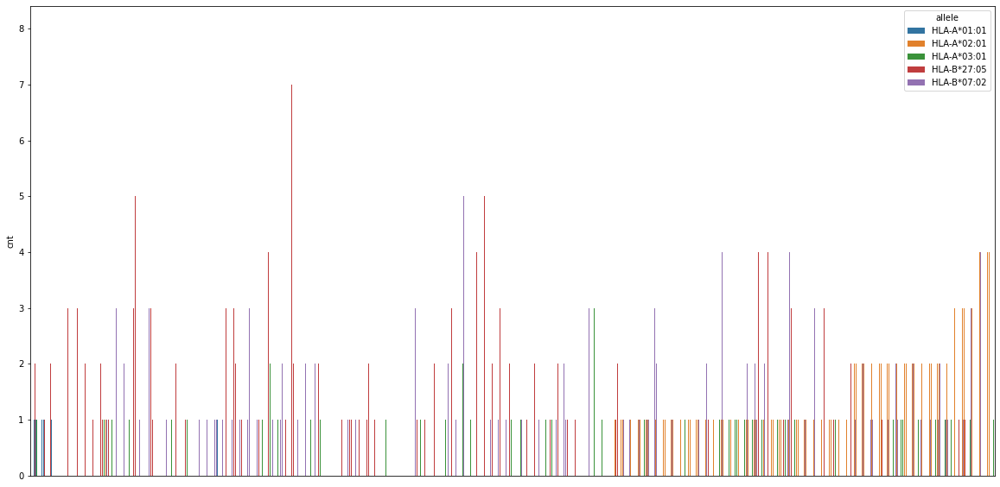

In [238]:

plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True).sort_values(by='diff')
# df = pd.concat([allele1_df, allele2_df]).reset_index(drop=True).sort_values(by='diff')
ax = sns.barplot(data=df_to_plot, x='path', y='cnt', hue='allele')
ax.set_xlabel('')
ax.set_xticks([])

<AxesSubplot:xlabel='path', ylabel='cnt'>

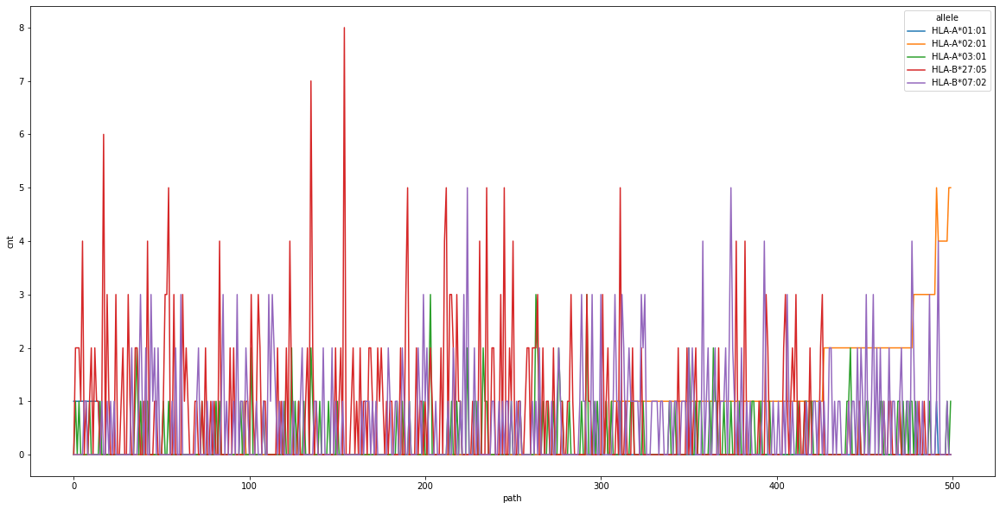

In [239]:
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
df_to_plot = pd.concat(per_allele_df.values()).reset_index(drop=True).sort_values(by='diff')

sns.lineplot(data=df_to_plot, x='path', y='cnt', hue='allele')



## Hierarhical clustering

In [19]:
df = per_name_representation_train["v"]["db"]
label_to_index = {label: i for i, label in enumerate(selected_alleles)}
df['label'] = df['allele'].map(label_to_index)
n_clusters = 2
labels = selected_alleles

In [20]:
X = df.drop(columns=['allele', 'label']).values

In [21]:
TOP = 2000
X = X.T[:TOP]

In [22]:
X.shape

(2000, 20234)

In [23]:
from sklearn.cluster import AgglomerativeClustering

In [24]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import pairwise_distances
import scipy.cluster.hierarchy as sch

[]

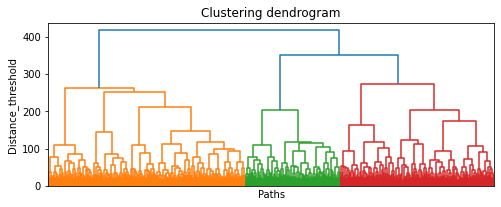

In [25]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(8, 3))
dendrogram = sch.dendrogram(sch.linkage(X, method='ward'), ax=ax)
ax.set_xlabel('Paths')
ax.set_ylabel('Distance_threshold')
ax.set_title(f"Clustering dendrogram")
ax.set_xticks([])

In [26]:

model = AgglomerativeClustering(
    n_clusters=None, linkage="ward", affinity='euclidean', distance_threshold=300
)
model.fit(X)

AgglomerativeClustering(distance_threshold=300, n_clusters=None)

In [27]:
unique_labels_counts = pd.Series(model.labels_).value_counts().sort_values(ascending=False)
unique_labels_counts

1    887
0    688
2    425
dtype: int64

In [28]:
probs_df = df[[i for i in range(X.shape[0])]]

In [29]:
path_to_label = {i:model.labels_[i] for i in range(X.shape[0])}

In [30]:
peptide_df = pd.DataFrame({"peptide": df.index.values, "allele": df['allele']})

In [31]:

for label in unique_labels_counts.index:
    # peptide_df[f'path_gr_{label}'] = np.exp(df[ [path for path, cur_label in path_to_label.items() if cur_label == label]]).mean(axis=1).values
    peptide_df[f'path_gr_{label}'] = df[ [path for path, cur_label in path_to_label.items() if cur_label == label]].max(axis=1).values


In [32]:
peptide_df['max_label'] = peptide_df[[f'path_gr_{label}' for label in path_to_label.values()]].idxmax(axis=1)
peptide_df['len'] = peptide_df['peptide'].str.len()
peptide_df

,peptide,allele,path_gr_1,path_gr_0,path_gr_2,max_label,len
PVSMTYLYNK,PVSMTYLYNK,HLA-A*03:01,-0.605025,-0.747053,-0.837191,path_gr_1,10
NYDLALKYF,NYDLALKYF,HLA-A*01:01,-0.627643,-0.753649,-0.816757,path_gr_1,9
TLKSFTVEK,TLKSFTVEK,HLA-A*03:01,-0.668720,-0.666581,-0.793029,path_gr_0,9
AIFTDASTV,AIFTDASTV,HLA-A*02:01,-0.541323,-0.462618,-0.680109,path_gr_0,9
KLEYLAPSY,KLEYLAPSY,HLA-A*01:01,-0.439348,-0.504456,-0.443379,path_gr_1,9
...,...,...,...,...,...,...,...
STPIVVQMTK,STPIVVQMTK,HLA-A*03:01,-0.721341,-0.623245,-0.866598,path_gr_0,10
FIGEGAGNLL,FIGEGAGNLL,HLA-A*02:01,-0.705627,-0.520432,-0.643436,path_gr_0,10
SSESLNHLLY,SSESLNHLLY,HLA-A*01:01,-0.582868,-0.794141,-0.708747,path_gr_1,10
FIFQSSMTK,FIFQSSMTK,HLA-A*03:01,-0.790528,-0.534366,-0.563820,path_gr_0,9


In [33]:
peptide_df.max_label.value_counts()

path_gr_1    8516
path_gr_0    7589
path_gr_2    4129
Name: max_label, dtype: int64

In [34]:
peptide_df.groupby(['max_label','allele', 'len'])['peptide'].count()

max_label  allele       len
path_gr_0  HLA-A*01:01  9      2147
                        10      961
           HLA-A*02:01  9      1588
                        10      690
           HLA-A*03:01  9      1426
                        10      777
path_gr_1  HLA-A*01:01  9      1750
                        10      763
           HLA-A*02:01  9      2094
                        10      948
           HLA-A*03:01  9      2027
                        10      934
path_gr_2  HLA-A*01:01  9       766
                        10      420
           HLA-A*02:01  9      1135
                        10      433
           HLA-A*03:01  9       960
                        10      415
Name: peptide, dtype: int64

0
1
2
0
1
2


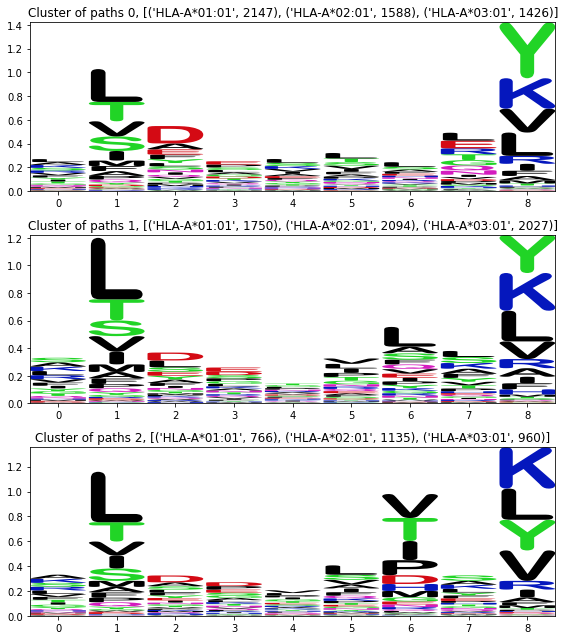

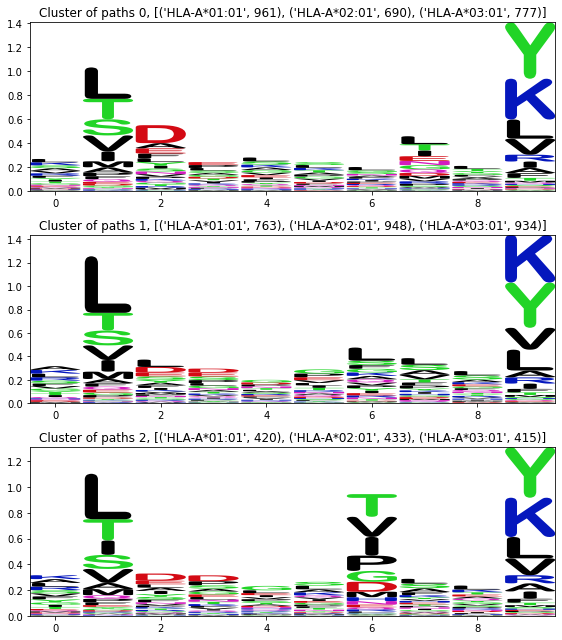

In [35]:
import matplotlib.pyplot as plt
import logomaker
for target_length in TARGET_LENGTHS:
    fig, axes = plt.subplots(nrows=len(unique_labels_counts), figsize=(8, 3*len(unique_labels_counts)))
    for i, label in enumerate(sorted(unique_labels_counts.index)):
        target_label = f'path_gr_{label}'
        print(i)
        # filtered_df =  peptide_df.sort_values(by=f'path_gr_{label}', ascending=False)[:400]
        filtered_df =  peptide_df[peptide_df['max_label'] == target_label]
        filtered_df = filtered_df[filtered_df['len'] == target_length]
        # filtered_df =  filtered_df.sort_values(by=target_label, ascending=False)[:1000]
        counts = filtered_df['allele'].value_counts()


        matrix = logomaker.alignment_to_matrix(filtered_df['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=axes[i])
        # counts_list = [(key, value) for key, value in sorted(counts.items())]
        counts = [(key, value) for key, value in sorted(counts.items())]
        ww_logo.ax.set_title(f"Cluster of paths {label}, {counts}")
    plt.tight_layout()


In [67]:
import logomaker
# check some cases
def make_logo(df):
    matrix = logomaker.alignment_to_matrix(df['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = filtered_df['allele'].value_counts()
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f" Allele counts: {counts.values}")

In [68]:
peptide_df['allele'].value_counts()

HLA-A*02:01    6892
HLA-A*01:01    6797
HLA-A*03:01    6537
Name: allele, dtype: int64

In [69]:
selected_alleles

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01']

In [53]:
filtered_df =  peptide_df[(peptide_df['len'] == 10) ]

filtered_df = filtered_df[filtered_df['allele'] == 'HLA-A*03:01']



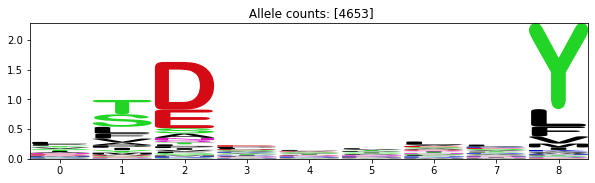

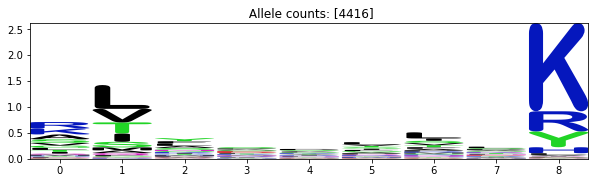

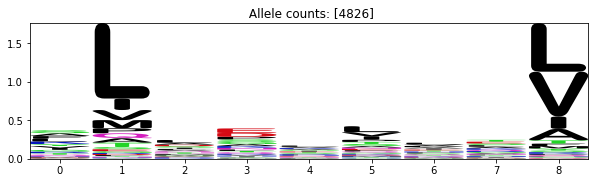

In [70]:
for allele in selected_alleles:
    filtered_df =  peptide_df[(peptide_df['len'] == 9) ]
    filtered_df = filtered_df[filtered_df['allele'] == allele]
    make_logo(filtered_df)


In [55]:
filtered_df =  peptide_df[(peptide_df['len'] == 10) ]

filtered_df = filtered_df[filtered_df['allele'] == 'HLA-A*01:01']


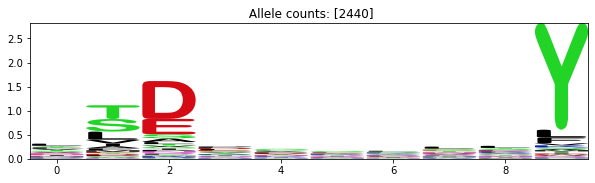

In [56]:
make_logo(filtered_df)

In [237]:
filtered_df = peptide_df[peptide_df.index.str[8] == 'R']
filtered_df = filtered_df[filtered_df['allele'] == 'HLA-A*01:01']



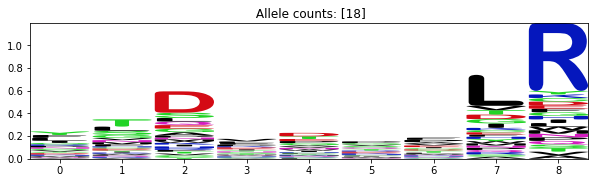

In [238]:
make_logo(filtered_df)

In [222]:
filtered_df['allele'].value_counts()

HLA-A*01:01    18
Name: allele, dtype: int64

In [121]:
df_bw_paths[[f's{i}' for i in range(11)]] = pd.DataFrame(df_bw_paths.path.tolist(), index= df_bw_paths.index)

In [122]:
df_bw_paths= df_bw_paths.drop(columns=['s0', 's10'])

In [123]:
df_bw_paths

,path,prob,s1,s2,s3,s4,s5,s6,s7,s8,s9
0,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-7.966576,s000,s007,s010,s011,s016,s019,s020,s025,s027
1,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-8.017974,s000,s007,s010,s011,s016,s019,s020,s025,s028
2,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-8.034995,s000,s007,s010,s011,s016,s017,s020,s025,s027
3,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-8.060473,s000,s007,s010,s011,s016,s019,s020,s023,s027
4,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-8.069983,s000,s007,s010,s012,s016,s019,s020,s025,s027
...,...,...,...,...,...,...,...,...,...,...,...
19678,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-12.273354,s000,s006,s008,s013,s014,s018,s021,s023,s026
19679,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-12.288216,s002,s006,s008,s013,s015,s019,s021,s023,s026
19680,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-12.325417,s002,s006,s008,s013,s014,s018,s021,s023,s026
19681,[0_run-9-3-st-baum-welch-alg-5-min_iters_model...,-12.422427,s000,s006,s008,s013,s015,s018,s021,s023,s026


In [307]:
X = df.drop(columns=['allele', 'label']).values
y = df['label'].values

In [ ]:
# Plot the distances
for index, metric in enumerate(["cosine", "euclidean", "cityblock"]):
    avg_dist = np.zeros((n_clusters, n_clusters))
    plt.figure(figsize=(5, 4.5))
    for i in range(n_clusters):
        for j in range(n_clusters):
            avg_dist[i, j] = pairwise_distances(
                X[y == i], X[y == j], metric=metric
            ).mean()
    avg_dist /= avg_dist.max()
    for i in range(n_clusters):
        for j in range(n_clusters):
            plt.text(
                i,
                j,
                "%5.3f" % avg_dist[i, j],
                verticalalignment="center",
                horizontalalignment="center",
            )

In [130]:
total_pivot_plus = per_name_representation_train["v"]["db"][[i for i in range(1000)]]

total_pivot_plus = total_pivot_plus.loc[(total_pivot_plus != -55).any(axis=1)]
for i in range(9):
    total_pivot_plus[f'a{i}'] = total_pivot_plus.index.str[i]

aa_columns = [f"a{i}" for i in range(9)]
total_pivot_plus[ aa_columns + [col for col in total_pivot_plus.columns if col not in aa_columns]].to_csv(f'embedding_for_phantasus.csv',sep="\t", index=True)

# Test clustering approaches
## Run PCA  first (as it's suggested by K-Means)
### Get pca objects

In [20]:
per_name_representation_train['v']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,allele
IGEIGVTAL,-0.991592,-1.117171,-1.003523,-1.253569,-1.110378,-1.366620,-0.867321,-0.878824,-1.001918,-1.120469,...,-0.991332,-1.246873,-1.119772,-1.140992,-0.996603,-1.235811,-1.175151,-1.321605,-1.115400,HLA-A*02:01
RSRRQTNTK,-1.308726,-1.185223,-1.184743,-1.089672,-0.970153,-0.988144,-1.315394,-1.187191,-1.319052,-1.310457,...,-1.182439,-1.202828,-1.054004,-1.115480,-1.200719,-1.000640,-0.869067,-0.924981,-1.202240,HLA-A*03:01
TLFNTVATL,-0.801007,-1.176860,-1.176380,-0.948620,-1.329685,-1.081368,-0.807676,-1.051682,-0.744728,-0.929884,...,-1.041612,-1.077560,-0.941624,-0.968717,-0.802853,-1.331817,-0.970017,-1.052747,-1.205839,HLA-A*02:01
ISESIKELQF,-1.275091,-1.150373,-1.273044,-0.996028,-0.940816,-0.894500,-1.150820,-1.275491,-1.285417,-1.276822,...,-1.018142,-0.907758,-1.162082,-1.144474,-1.280102,-1.142834,-1.040970,-0.858733,-0.907170,HLA-A*01:01
GLMHSIGLGY,-1.083074,-1.207283,-1.206803,-1.001474,-1.186700,-1.134223,-1.089742,-1.083474,-1.093399,-1.210581,...,-1.189275,-1.360000,-1.149504,-1.216328,-0.910875,-1.224862,-1.016566,-1.286666,-1.315291,HLA-A*01:01


In [21]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_cols=["allele","dataset", "label"],  whiten=True):
    X = df_concat.drop(columns=target_cols, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    print(f"Shape {X.shape}")
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_cols=["allele","dataset", "label"]):
    X = data.drop(columns=target_cols, errors='ignore').values
    print(f"Shape of X {X.shape}")
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df




In [22]:
pca_bw = get_pca(pd.concat([per_name_representation_train['bw']['db']]), n_components=15)
pca_bwv = get_pca(pd.concat([per_name_representation_train['bwv']['db']]), n_components=15)
pca_v = get_pca(pd.concat([per_name_representation_train['v']['db']]), n_components=15)

Shape (20206, 1518)
Explained variation per principal component: [0.35487644 0.2351549  0.10058366 0.06329311 0.03276865 0.02814549
 0.02594231 0.02173573 0.01926236 0.01755434 0.01233437 0.01150116
 0.01041534 0.00934995 0.00882132]
Shape (20206, 862)
Explained variation per principal component: [0.16385004 0.16052658 0.12871284 0.0944812  0.0805802  0.05691729
 0.05643195 0.04652912 0.03484393 0.03272692 0.03187896 0.02835911
 0.01604814 0.01302012 0.01116981]
Shape (20206, 2000)
Explained variation per principal component: [0.22949592 0.09872516 0.09327908 0.0727876  0.05070241 0.04756222
 0.04038642 0.03584412 0.03509229 0.02902384 0.02457499 0.0210586
 0.02034723 0.01738495 0.01524995]


<AxesSubplot:>

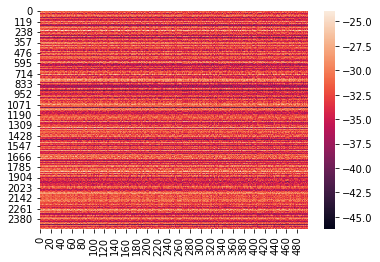

In [44]:
sns.heatmap(per_name_representation_test['bw']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

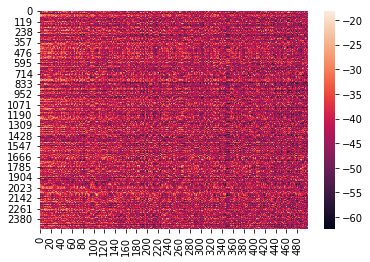

In [45]:
sns.heatmap(per_name_representation_test['bwv']['db'].drop(columns=["allele"]).values)

<AxesSubplot:>

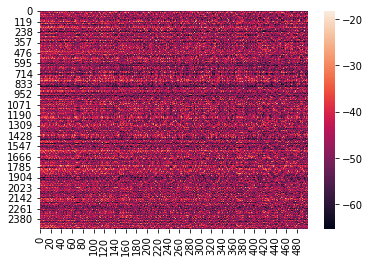

In [46]:
sns.heatmap(per_name_representation_test['v']['db'].drop(columns=["allele"]).values)

In [39]:
df = per_name_representation_train['bwv']['db'].drop(columns=["allele"]).copy().T

In [40]:
def collect_embeddings_with_pca_or_without(train_data, test_data, pca):
    columns_to_drop = ["dataset", "allele", "label"]
    if pca:
        train_embedding = get_pca_embedding(pca, train_data)
        test_embedding = get_pca_embedding(pca, test_data)
    else:
        train_embedding = train_data.drop(columns=columns_to_drop, errors='ignore')
        test_embedding = test_data.drop(columns=columns_to_drop, errors='ignore')
    if "allele" in train_data.columns:
        alleles_train = train_data['allele'].values
        alleles_test = test_data['allele'].values


    train_df = pd.DataFrame(train_embedding, index=train_data.index)
    train_df['dataset'] = 'Train'
    train_df['allele'] = alleles_train
    test_df = pd.DataFrame(test_embedding, index=test_data.index)
    test_df['dataset'] = 'Test'
    test_df['allele'] = alleles_test

    total_embedding = pd.concat([train_df, test_df])
    return total_embedding

In [41]:
def get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v):
    per_model_embedding_result= dict()
    for model_key in ['bw', 'bwv', 'v']:
        if model_key == 'bw':
            model_name = 'bw'
            pca = pca_bw
        elif model_key == 'bwv':
            model_name = 'bwv'
            pca = pca_bwv
        else:
            model_name = 'v'
            pca = pca_v

        train_repr = per_name_representation_train[model_name]['db'].copy()
        test_repr = per_name_representation_test[model_name]['db'].copy()
        total_embedding_db = collect_embeddings_with_pca_or_without(train_repr, test_repr, pca)
        total_embedding_db['dataset'] = total_embedding_db['dataset'] + '_db'

        total_embedding = pd.concat([total_embedding_db])
        per_model_embedding_result[model_key] = total_embedding
    return per_model_embedding_result


In [42]:
%%time
per_model_embedding_result_without_pca = get_embedding_for_selected_models_using_pca(None, None, None)
per_model_embedding_result = get_embedding_for_selected_models_using_pca(pca_bw, pca_bwv, pca_v)
# per_model_embedding_result_w = get_embedding_for_selected_models_using_pca(pca_b_w, pca_i_w)

Shape of X (20234, 1518)
Shape of X (5328, 1518)
Shape of X (20234, 862)
Shape of X (5328, 862)
Shape of X (20234, 2000)
Shape of X (5328, 2000)
Wall time: 8.75 s


In [47]:
per_model_embedding_result_without_pca['bw'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,Train_db,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,Train_db,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,Train_db,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,Train_db,HLA-A*03:01


In [48]:
per_model_embedding_result_without_pca['bwv'].head()

,0,1,2,3,4,5,6,7,8,9,...,1992,1993,1994,1995,1996,1997,1998,1999,dataset,allele
ILSVSSFLFV,-0.375824,-0.458435,-0.438305,-0.462972,-0.399262,-0.375359,-0.307893,-0.396597,-0.424391,-0.526497,...,-0.690939,-0.748143,-0.797170,-0.690649,-0.696509,-0.549402,-0.656650,-0.580109,Train_db,HLA-A*02:01
YLGPRVCWL,-0.375384,-0.375884,-0.318415,-0.453251,-0.469359,-0.384728,-0.410935,-0.332883,-0.527944,-0.381633,...,-0.512078,-0.637890,-0.651993,-0.668445,-0.778125,-0.581005,-0.543768,-0.582657,Train_db,HLA-A*02:01
QTCLELERY,-0.490758,-0.573580,-0.576579,-0.549482,-0.576087,-0.584300,-0.417656,-0.526961,-0.325174,-0.647071,...,-0.732136,-0.849313,-0.788534,-0.601646,-0.662889,-0.646481,-0.783966,-0.643668,Train_db,HLA-A*01:01
YTIERIFNAK,-0.470495,-0.553105,-0.628358,-0.386680,-0.564470,-0.555947,-0.510853,-0.503916,-0.348079,-0.556329,...,-0.557415,-0.681102,-0.640245,-0.638204,-0.625053,-0.591918,-0.765382,-0.705399,Train_db,HLA-A*03:01
TAYGPNGMNK,-0.507488,-0.507989,-0.432012,-0.592135,-0.530785,-0.420424,-0.549782,-0.379522,-0.602320,-0.366064,...,-0.568634,-0.643238,-0.670440,-0.651408,-0.634305,-0.561511,-0.578042,-0.655989,Train_db,HLA-A*03:01


In [49]:
per_name_representation_train['bw']['db'].head()

,0,1,2,3,4,5,6,7,8,9,...,1991,1992,1993,1994,1995,1996,1997,1998,1999,allele
ILSVSSFLFV,-0.364700,-0.381235,-0.367528,-0.378544,-0.371532,-0.351285,-0.366476,-0.361727,-0.388066,-0.349998,...,-0.413016,-0.438859,-0.464207,-0.405298,-0.479072,-0.384629,-0.439330,-0.419626,-0.406906,HLA-A*02:01
YLGPRVCWL,-0.374002,-0.369963,-0.375464,-0.363823,-0.388018,-0.381692,-0.384524,-0.392517,-0.383978,-0.387589,...,-0.408443,-0.410033,-0.444902,-0.463343,-0.438130,-0.434872,-0.426301,-0.446673,-0.479272,HLA-A*02:01
QTCLELERY,-0.389160,-0.398793,-0.392251,-0.411826,-0.405771,-0.385542,-0.391964,-0.351665,-0.415405,-0.394036,...,-0.445261,-0.476823,-0.481462,-0.469280,-0.492324,-0.443472,-0.422930,-0.480558,-0.461514,HLA-A*01:01
YTIERIFNAK,-0.355430,-0.371965,-0.358258,-0.369274,-0.369446,-0.372350,-0.354239,-0.358270,-0.385980,-0.378247,...,-0.426974,-0.461023,-0.447076,-0.439204,-0.427925,-0.459893,-0.415830,-0.422495,-0.515466,HLA-A*03:01
TAYGPNGMNK,-0.481032,-0.470816,-0.471870,-0.453353,-0.481343,-0.498497,-0.516707,-0.511324,-0.471128,-0.490691,...,-0.458310,-0.486136,-0.465521,-0.448926,-0.452600,-0.524882,-0.466095,-0.473271,-0.494837,HLA-A*03:01


In [43]:
from collections import defaultdict
from sklearn.cluster import KMeans

def cluster_total_embedding(total_embedding_dfs, per_model_predictor):
    total_clustering_result = defaultdict(list)
    for m_key in total_embedding_dfs.keys():
        # print(f"model_key {m_key}")
        total_model_df =  total_embedding_dfs[m_key].copy()
        representation_df = total_model_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
        representation_df['label'] = per_model_predictor[m_key].predict(representation_df.values)
        representation_df['dataset'] = total_model_df['dataset']

        total_clustering_result[m_key] = representation_df

    return total_clustering_result

In [44]:
def clustering_experiment(total_embedding_df, cluster_counts):
    """
        Train will be used for training
        All other datasets will be fitted
    """

    per_cluster_count_result = dict()
    for cluster_count in cluster_counts:
        print(f"cluster_count {cluster_count}")
        # bw
        kmeans_bw = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bw'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bw.fit(train_data)
        # bwv
        kmeans_bwv = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['bwv'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore').values
        kmeans_bwv.fit(train_data)

        # bwv
        kmeans_v = KMeans(n_clusters=cluster_count)
        total_model_df = total_embedding_df['v'].copy()
        #extract train_data ensure no peptide columns
        train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
        train_data = train_df.drop(columns=["dataset", "peptide","allele"],  errors='ignore').values
        kmeans_v.fit(train_data)
        # # immmune model
        # total_model_df = total_embedding_df['mi'].copy()
        # kmeans_i = KMeans(n_clusters= cluster_count)
        # #extract train_data ensure no peptide columns
        # train_df =total_model_df[total_model_df['dataset'] == f'Train_di']
        # train_data = train_df.drop(columns=["dataset", "peptide"],  errors='ignore').values
        # kmeans_i.fit(train_data)

        total_clustering_result = cluster_total_embedding(total_embedding_df, {"bw":kmeans_bw , "bwv":kmeans_bwv, "v": kmeans_v})
        per_cluster_count_result[cluster_count] = total_clustering_result
    return per_cluster_count_result

In [45]:
cluster_counts = [2 , 4,  5]
per_cluster_count_result_pca = clustering_experiment(per_model_embedding_result, cluster_counts=cluster_counts)
per_cluster_count_result_repr = clustering_experiment(per_model_embedding_result_without_pca, cluster_counts=cluster_counts)

cluster_count 2
cluster_count 4
cluster_count 5
cluster_count 2
cluster_count 4
cluster_count 5


## Plot PCA plots

3    3794
0    3145
1    2168
2    1940
4     686
Name: label, dtype: int64


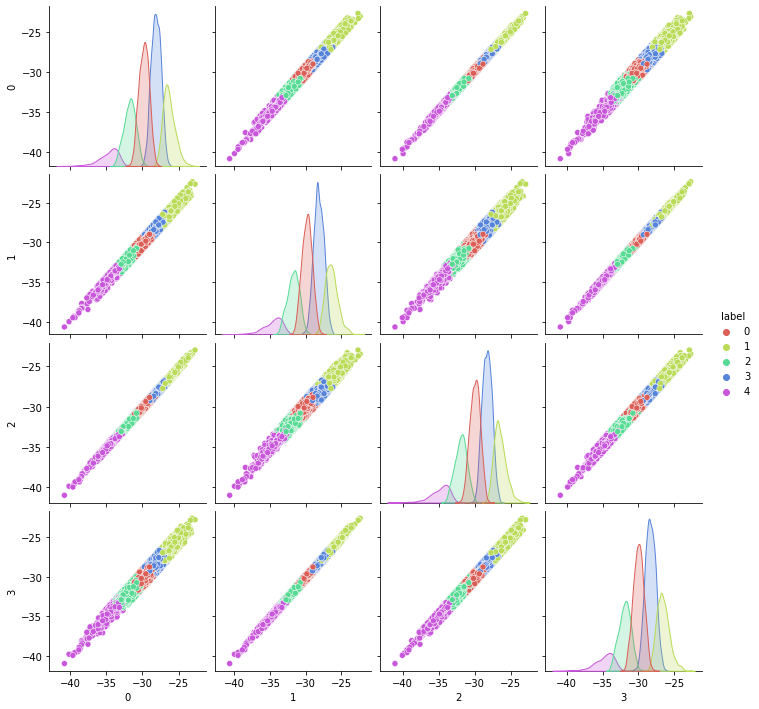

In [108]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))


4    3045
0    2433
2    2372
1    2096
3    1787
Name: label, dtype: int64


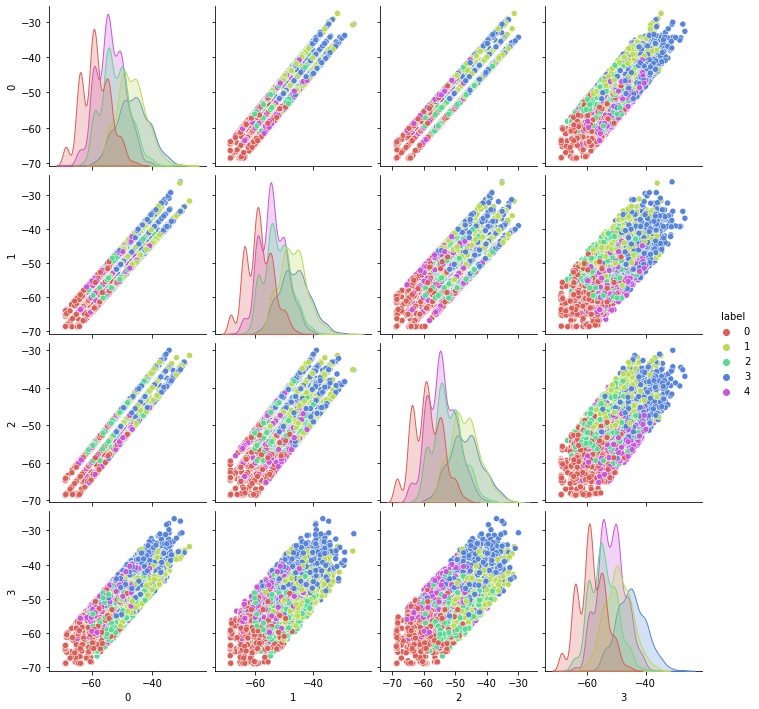

In [109]:
clusters_count = 5
sample_df = per_cluster_count_result_repr[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

2    3511
0    3262
3    2737
1    1207
4    1016
Name: label, dtype: int64


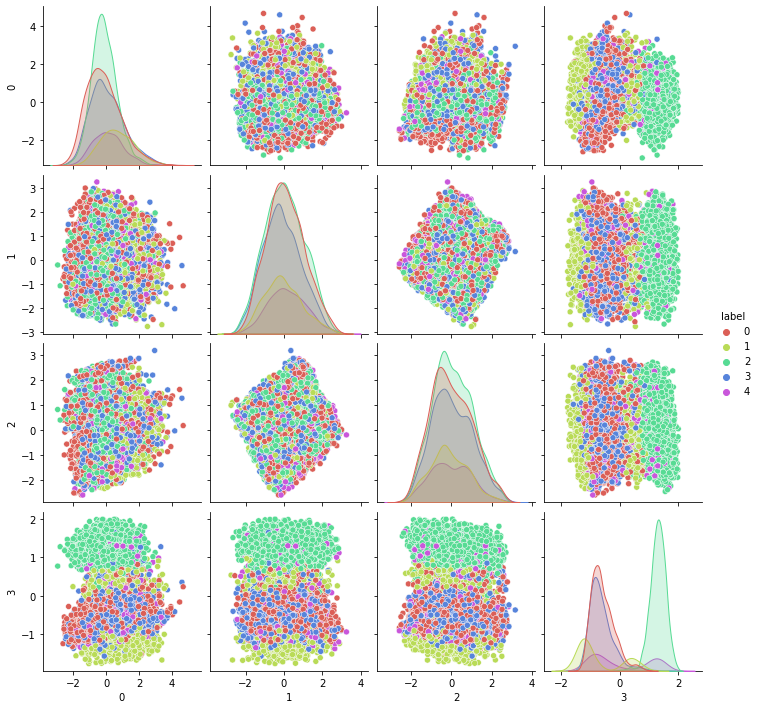

In [57]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bw']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4276
4    3622
0    3598
3    3176
2    2798
Name: label, dtype: int64


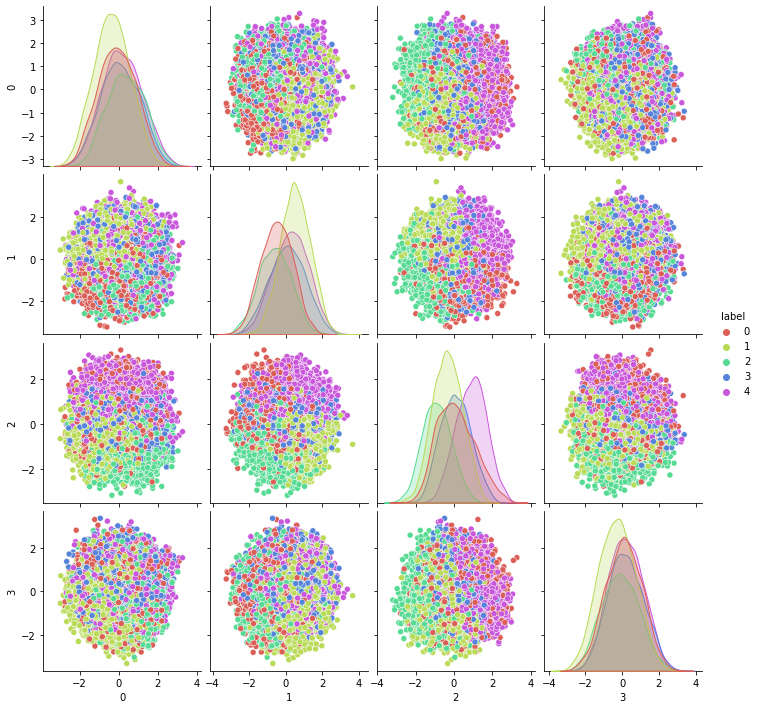

In [68]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['v']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

1    4152
3    2817
4    2705
2    1567
0     492
Name: label, dtype: int64


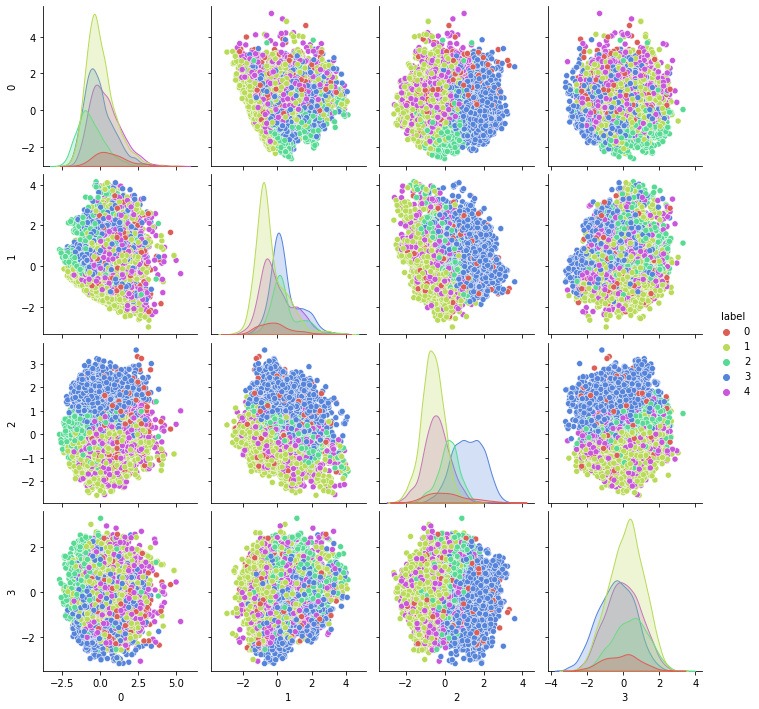

In [86]:
clusters_count = 5
sample_df = per_cluster_count_result_pca[clusters_count]['bwv']
sample_df = sample_df.loc[~sample_df['dataset'].str.startswith('Generated')]
pca_first_components = sample_df[[0,1,2,3, 'label']].copy()
print(pca_first_components['label'].value_counts())
df = pca_first_components.reset_index(drop=True)
sns.pairplot(df, hue='label', palette=sns.color_palette("hls", clusters_count))

In [96]:
df

,0,1,2,3,label
0,0.999295,0.387324,0.678455,-0.490383,3
1,0.108097,0.021062,0.669517,1.430231,3
2,-0.489513,0.130982,2.365413,-0.590073,0
3,0.476359,-0.651274,1.616374,-0.909632,0
4,0.215536,1.019187,-1.049684,0.503872,4
...,...,...,...,...,...
11728,1.826773,0.694532,-0.540280,0.434760,0
11729,1.655829,0.138762,-0.061199,2.225898,3
11730,-0.679647,-1.219310,-0.063222,1.409131,1
11731,0.944976,-0.191033,0.393523,1.156476,3


# Make UMAP object

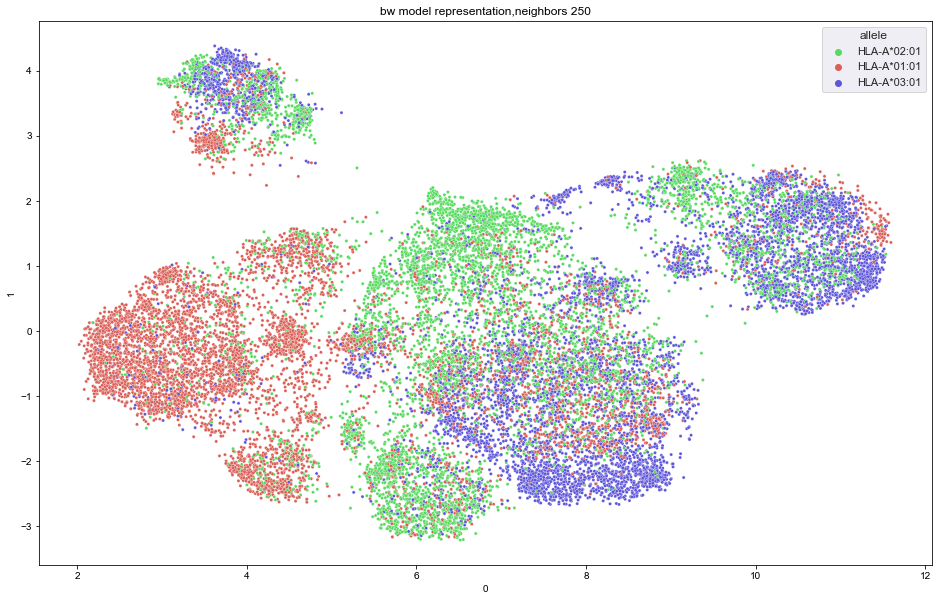

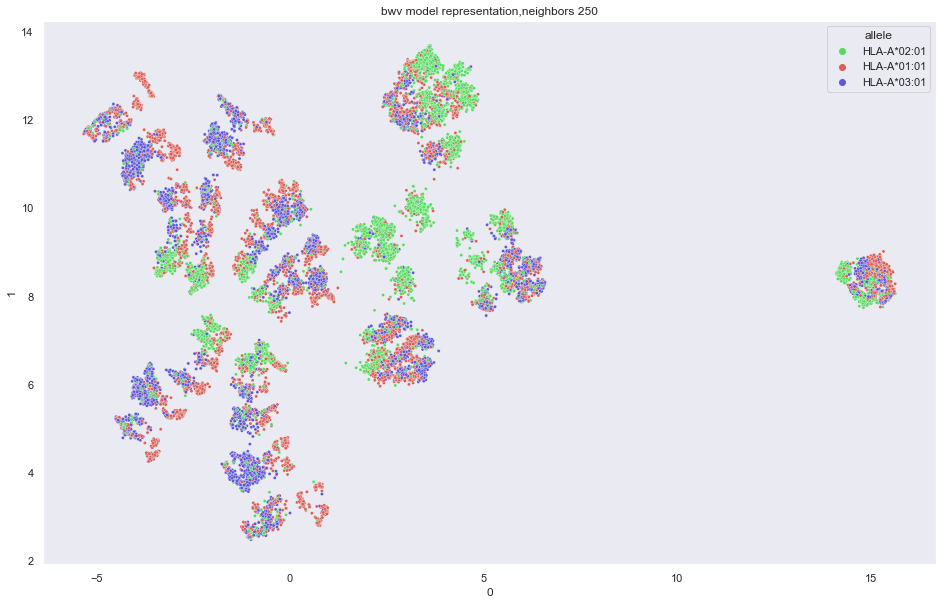

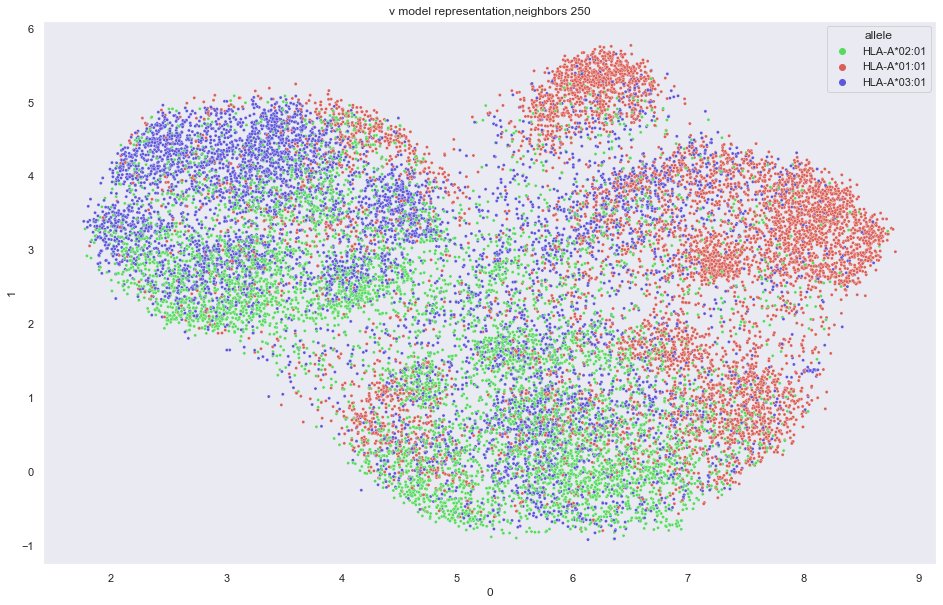

In [47]:
import umap
from sklearn.preprocessing import StandardScaler
from collections import defaultdict
import matplotlib.pyplot as plt

def get_reducer(data,n_neighbors=15, n_components=2):
    reducer = umap.UMAP(n_neighbors=n_neighbors, n_components=n_components)
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    reducer.fit(scaled_data)
    return reducer, scaler

def get_umap_embedding(reducer, scaler,  data):
    scaled_data = scaler.fit_transform(data)
    umap_result = reducer.transform(scaled_data)
    df = pd.DataFrame(umap_result, index=data.index)
    return df


def define_pallete(df, hue_column):
    unique_hue_values = sorted(df[hue_column].unique())
    source_pallete = sns.color_palette("hls", len(unique_hue_values))
    colors ={hue_value: source_pallete[i] for i, hue_value in enumerate(unique_hue_values)}
    return colors

def make_scatter_plot_sns(source_df, title, colors=None, hue_column='dataset' ):
    source_df = source_df.sample(frac=1)
    fig,ax = plt.subplots(figsize=(16, 10))
    sns.set_theme(style="dark")
    if colors is None:
        colors = define_pallete(source_df,hue_column )
    ax = sns.scatterplot(data=source_df, x=source_df.columns[0], y=source_df.columns[1], hue=hue_column,ax=ax, picker=4, s=10,
                         palette=colors)
    ax.set_title(title)
    return fig


In [46]:
n = 250
for model, total_model_df in per_model_embedding_result.items():
    train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
    test_df = total_model_df[total_model_df['dataset'] == f'Test_db']

    train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    test_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    reducer_b, scaler_b = get_reducer(train_data, n_neighbors=n)

    train_embedding = get_umap_embedding(reducer_b, scaler_b, train_data)
    train_embedding['allele'] = train_df['allele']
    train_embedding['dataset'] = train_df['dataset']
    test_embedding = get_umap_embedding(reducer_b, scaler_b, test_data)
    test_embedding['allele'] = test_df['allele']
    test_embedding['dataset'] = test_df['dataset']
    fig = make_scatter_plot_sns(train_embedding, title=f"{model} model representation,neighbors {n}", hue_column='allele')


Wall time: 1min 1s


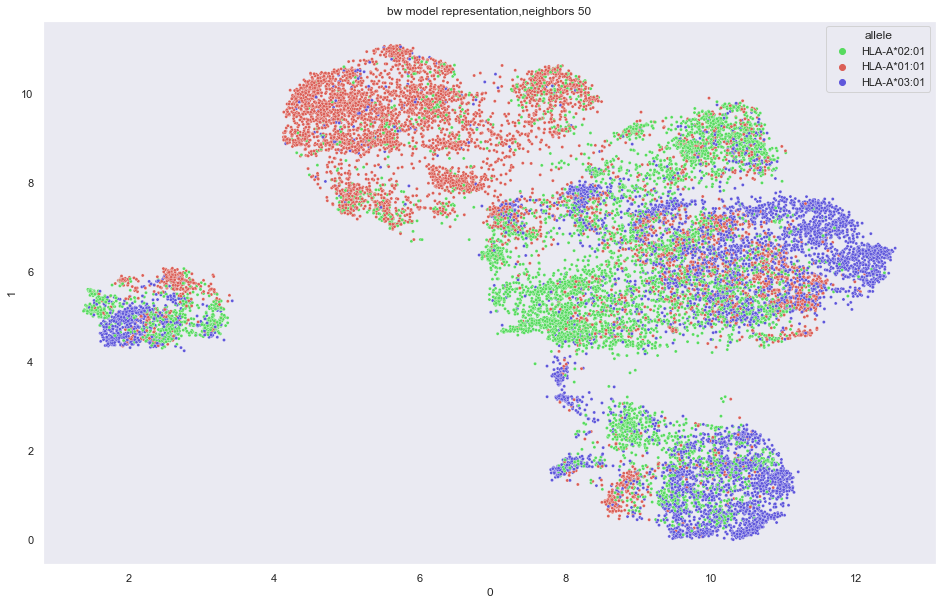

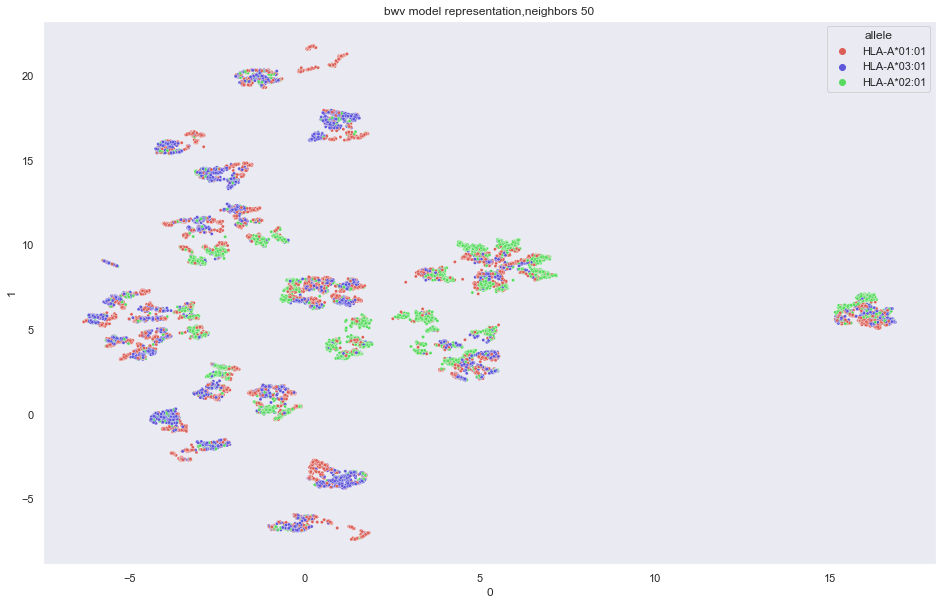

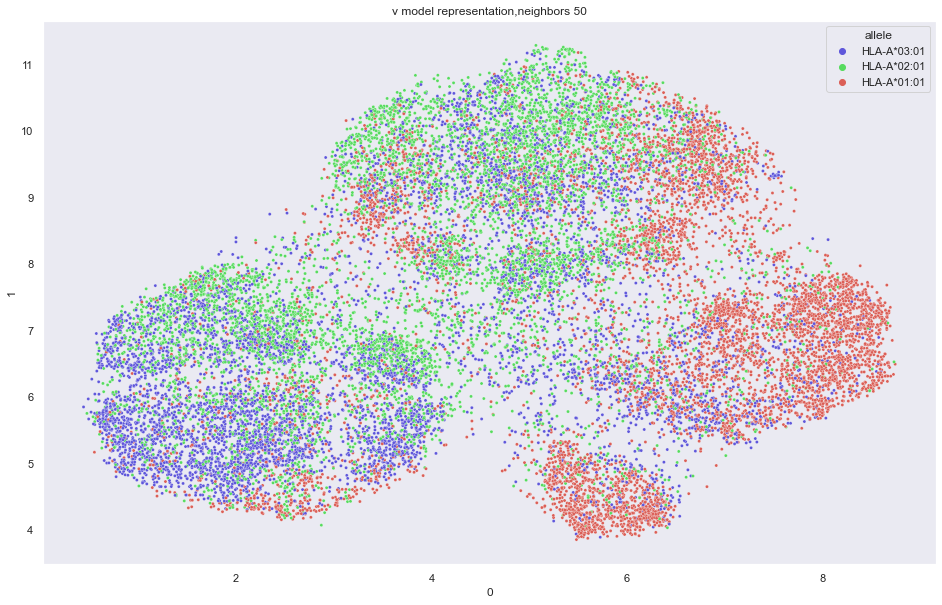

In [58]:
%%time
n = 50

train_embedding_bw = None
train_embedding_bwv = None
train_embedding_v= None

for model, total_model_df in per_model_embedding_result.items():
    train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
    test_df = total_model_df[total_model_df['dataset'] == f'Test_db']

    train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    test_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    reducer_b, scaler_b = get_reducer(train_data, n_neighbors=n)
    train_embedding = get_umap_embedding(reducer_b, scaler_b, train_data)
    train_embedding['allele'] = train_df['allele']
    train_embedding['dataset'] = train_df['dataset']
    test_embedding = get_umap_embedding(reducer_b, scaler_b, test_data)
    test_embedding['allele'] = test_df['allele']
    test_embedding['dataset'] = test_df['dataset']
    train_embedding['length'] = train_embedding.index.str.len()
    if model == "bw":
        train_embedding_bw = train_embedding
    elif model == 'bwv':
        train_embedding_bwv = train_embedding
    elif model == 'v':
        train_embedding_v = train_embedding

    fig = make_scatter_plot_sns(train_embedding, title=f"{model} model representation,neighbors {n}", hue_column='allele')

In [70]:
def make_logo(df, length=9):
    filtered = df[df['length'] == length]
    matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    counts = df['allele'].value_counts()
    # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold')
    ww_logo.ax.set_title(f" Allele counts: {counts}")

def select_rectangle(df, x1, x2, y1, y2):
    filtered_df = df[(df[0] > x1) & (df[0] < x2) & (df[1] > y1) & (df[1] < y2)]
    filtered_df['peptide'] = filtered_df.index
    return filtered_df



In [81]:
counts = train_embedding['allele'].value_counts()
counts

HLA-A*02:01    6888
HLA-A*01:01    6807
HLA-A*03:01    6539
Name: allele, dtype: int64

NameError: name 'collections' is not defined

In [71]:
train_embedding = train_embedding_v

In [72]:
filtered_1 = select_rectangle(train_embedding, 0, 4, 0, 8)
filtered_2 = select_rectangle(train_embedding, 5, 7, 0, 5.2)

filtered_3 = select_rectangle(train_embedding, 6.1, 10, 5, 7.5)
filtered_4 = select_rectangle(train_embedding, 3, 8, 8, 15)

# #
# #
filtered_5 = select_rectangle(train_embedding, 4, 6, 5.5, 7.5)
filtered_6 = select_rectangle(train_embedding, 3.2, 4, 0, 7.5)
# #
# filtered_7 =  select_rectangle(train_embedding, 8.3, 10, 7, 20)

C:\Users\denkl\AppData\Local\Temp/ipykernel_14804/1210186331.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['peptide'] = filtered_df.index


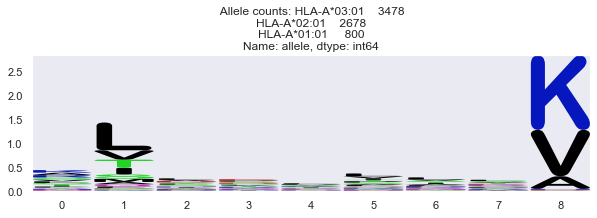

In [73]:
make_logo(filtered_1)

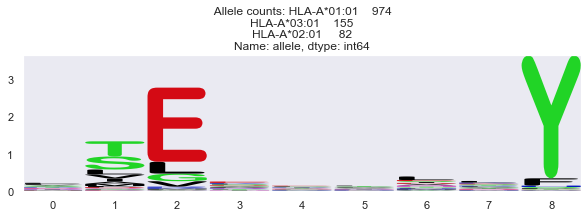

In [74]:
make_logo(filtered_2)

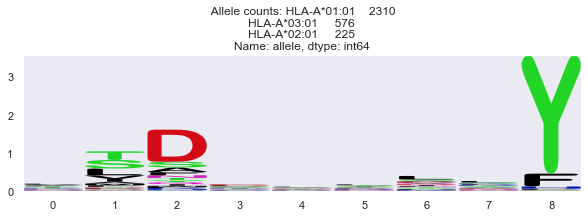

In [75]:
make_logo(filtered_3)

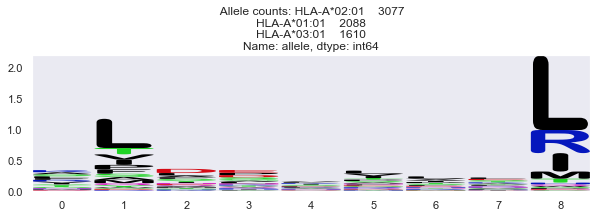

In [76]:
make_logo(filtered_4)

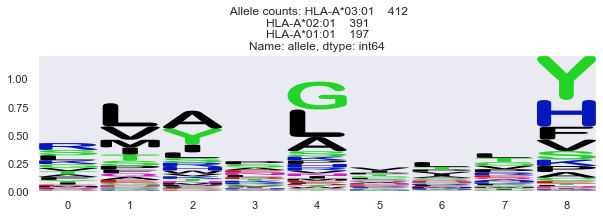

In [77]:
make_logo(filtered_5)

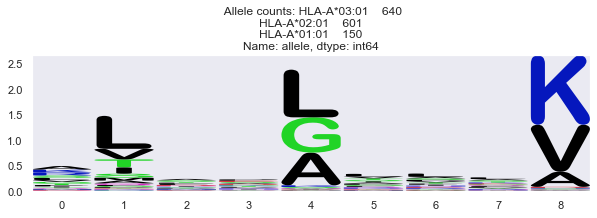

In [78]:
make_logo(filtered_6)

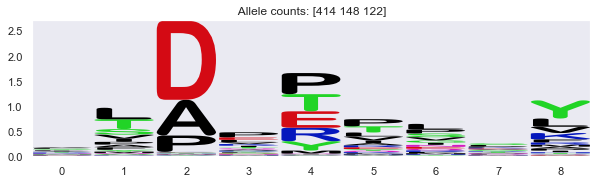

In [101]:
make_logo(filtered_7)

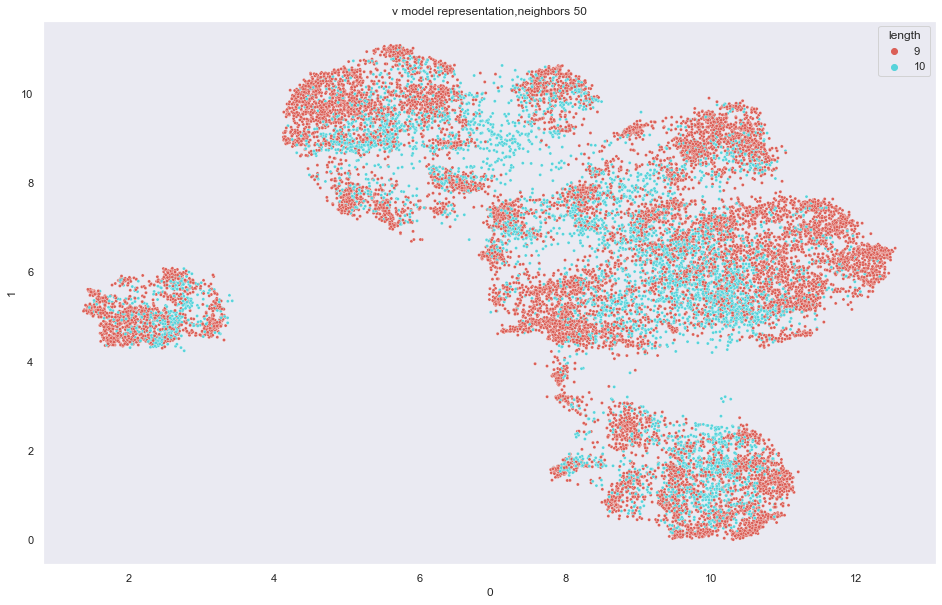

In [59]:
fig = make_scatter_plot_sns(train_embedding_bw, title=f"{model} model representation,neighbors {n}", hue_column='length')

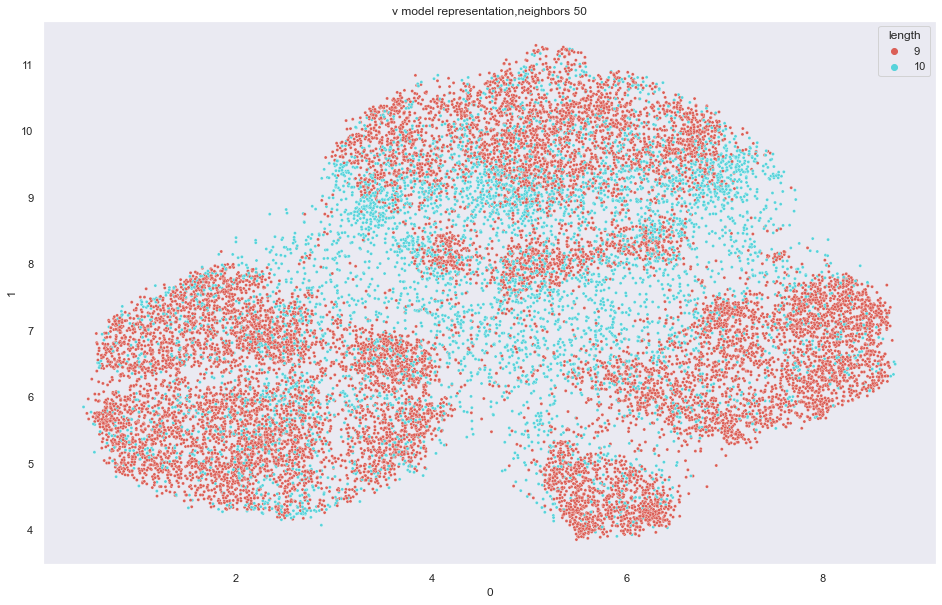

In [60]:
fig = make_scatter_plot_sns(train_embedding_v, title=f"{model} model representation,neighbors {n}", hue_column='length')

Wall time: 36.3 s


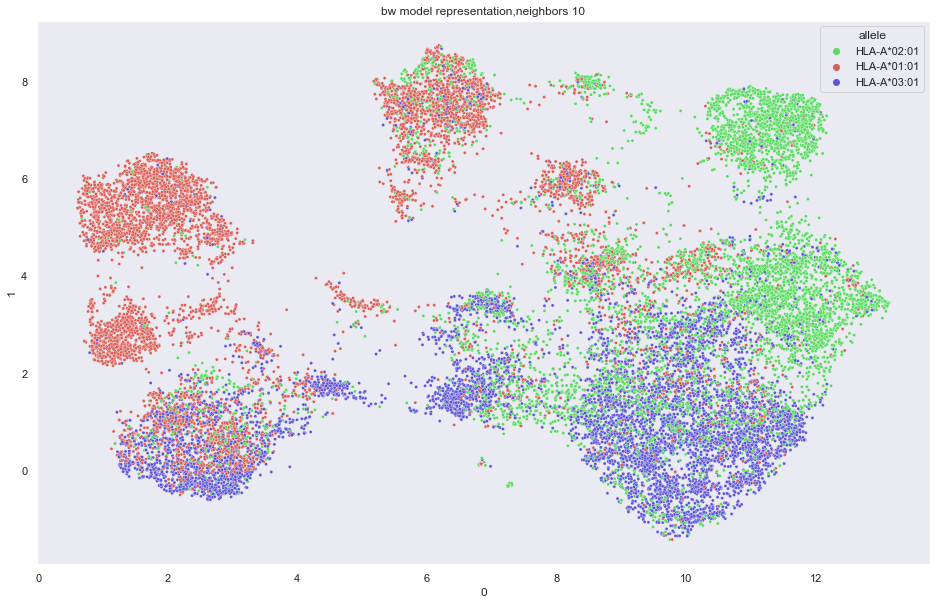

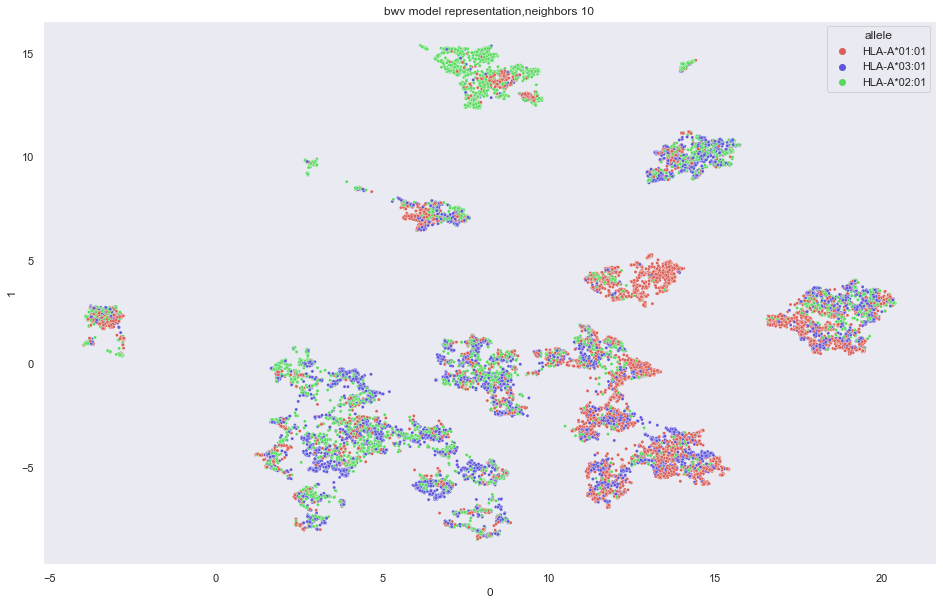

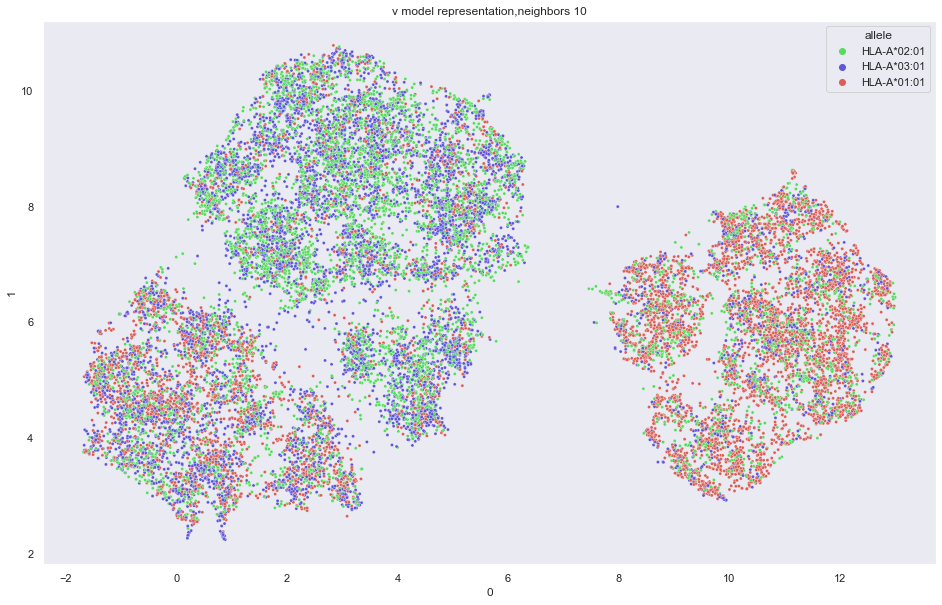

In [102]:
%%time
# another number of neighbours

n = 10
for model, total_model_df in per_model_embedding_result.items():
    train_df = total_model_df[total_model_df['dataset'] == f'Train_db']
    test_df = total_model_df[total_model_df['dataset'] == f'Test_db']

    train_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    test_data = train_df.drop(columns=["dataset", "peptide", "allele"],  errors='ignore')
    reducer_b, scaler_b = get_reducer(train_data, n_neighbors=n)

    train_embedding = get_umap_embedding(reducer_b, scaler_b, train_data)
    train_embedding['allele'] = train_df['allele']
    train_embedding['dataset'] = train_df['dataset']
    test_embedding = get_umap_embedding(reducer_b, scaler_b, test_data)
    test_embedding['allele'] = test_df['allele']
    test_embedding['dataset'] = test_df['dataset']
    fig = make_scatter_plot_sns(train_embedding, title=f"{model} model representation,neighbors {n}", hue_column='allele')

In [ ]:
import logomaker
allele_name = 'HLA-A*03:01'
binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][9]
matrix = logomaker.alignment_to_matrix(binders_array)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
ww_logo.ax.set_title(f"Allele {allele_name}")


In [ ]:
import logomaker
allele_name = 'HLA-A*01:01'
binders_array = per_allele_per_kfold_per_length_binders_train[allele_name][0][9]
matrix = logomaker.alignment_to_matrix(binders_array)
info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold',)
ww_logo.ax.set_title(f"Allele {allele_name}")